<a href="https://colab.research.google.com/github/Nilamsari01/Pengolahan_Citra_Digital/blob/main/NilamSari_F1G124046.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

/tmp/ipykernel_967/2943410412.py:23: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  plt.hist(img.ravel(), 256, [0,256], color='gray')


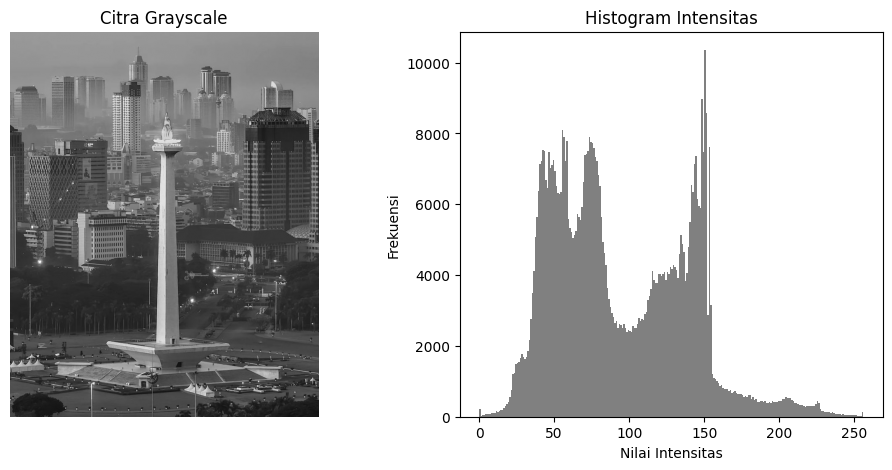

Mean: 94.34
Standar Deviasi: 44.82
Variansi: 2008.69
Entropi: 7.25


In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.measure import shannon_entropy

# Baca citra grayscale
img = cv2.imread('/content/gambar1.jpg', 0)

# Statistik dasar
mean_val = np.mean(img)
std_val = np.std(img)
var_val = np.var(img)
entropy_val = shannon_entropy(img)

# Histogram
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.imshow(img, cmap='gray')
plt.title('Citra Grayscale')
plt.axis('off')

plt.subplot(1,2,2)
plt.hist(img.ravel(), 256, [0,256], color='gray')
plt.title('Histogram Intensitas')
plt.xlabel('Nilai Intensitas')
plt.ylabel('Frekuensi')
plt.show()

print(f"Mean: {mean_val:.2f}")
print(f"Standar Deviasi: {std_val:.2f}")
print(f"Variansi: {var_val:.2f}")
print(f"Entropi: {entropy_val:.2f}")

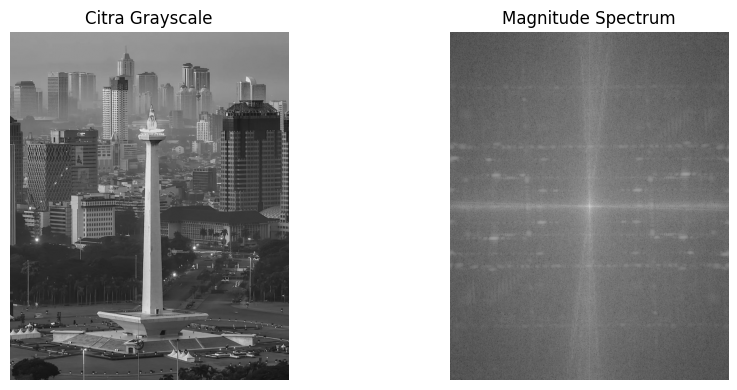

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread('/content/gambar1.jpg', cv2.IMREAD_GRAYSCALE)

f = np.fft.fft2(img)
fshift = np.fft.fftshift(f)

magnitude_spectrum = 20 * np.log(np.abs(fshift) + 1)

plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.title('Citra Grayscale')
plt.imshow(img, cmap='gray')
plt.axis('off')

plt.subplot(1,2,2)
plt.title('Magnitude Spectrum')
plt.imshow(magnitude_spectrum, cmap='gray')
plt.axis('off')

plt.tight_layout()
plt.show()

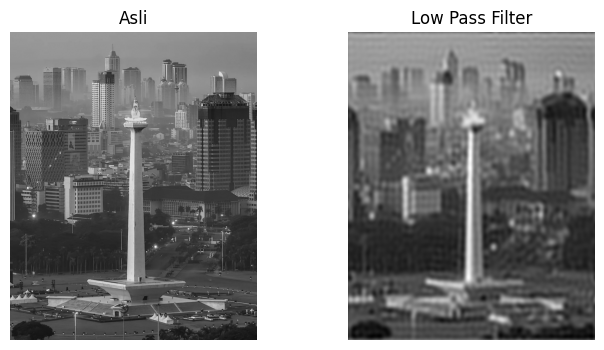

In [3]:
rows, cols = img.shape
crow, ccol = rows//2, cols//2

mask = np.zeros((rows, cols), np.uint8)
cv2.circle(mask, (ccol, crow), 40, 1, -1)

fshift_lp = fshift * mask
f_ishift = np.fft.ifftshift(fshift_lp)
img_lp = np.abs(np.fft.ifft2(f_ishift))

plt.figure(figsize=(8,4))
plt.subplot(1,2,1); plt.title("Asli")
plt.imshow(img, cmap='gray'), plt.axis('off')

plt.subplot(1,2,2); plt.title("Low Pass Filter")
plt.imshow(img_lp, cmap='gray'), plt.axis('off')
plt.show()

<Figure size 800x400 with 0 Axes>

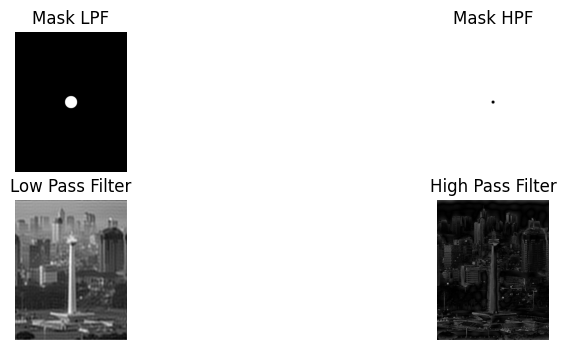

In [4]:
mask_hpf = np.ones((rows, cols), np.uint8)
cv2.circle(mask_hpf, (ccol, crow), 10, 0, -1)

fshift_hp = fshift * mask_hpf
f_ishift = np.fft.ifftshift(fshift_hp)
img_hp = np.abs(np.fft.ifft2(f_ishift))

img_hpf_norm = cv2.normalize(img_hp, None, 0, 255, cv2.NORM_MINMAX)
img_hpf_norm = img_hpf_norm.astype(np.uint8)


plt.figure(figsize=(8,4))

plt.figure(figsize=(10,4))
plt.subplot(2,2,1)
plt.title('Mask LPF')
plt.imshow(mask, cmap='gray')
plt.axis('off')

plt.subplot(2,2,2)
plt.title('Mask HPF')
plt.imshow(mask_hpf, cmap='gray')
plt.axis('off')

plt.subplot(2,2,3); plt.title("Low Pass Filter")
plt.imshow(img_lp, cmap='gray'), plt.axis('off')

plt.subplot(2,2,4); plt.title("High Pass Filter")
plt.imshow(img_hpf_norm, cmap='gray'), plt.axis('off')
plt.show()